# Lightning-Caused Wildfire Detection: Results

This notebook gathers every result produced so far for the August 2020 California lightning siege. It only **reads** the data and result files in this folder, except for re-running the fast matching and validation steps (a few seconds) so their output is shown here.

**Contents**
1. Data overview
2. Matching prototype
3. Chance baseline and parameter tuning
4. Validation against FPA FOD
5. Streaming pipeline benchmarks
6. Precision/recall trade-off
7. MongoDB geospatial queries
8. Remaining work

See `README.md` for how each file was produced.

In [1]:
import os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
BLUE, ORANGE, RED, GREY, TEAL = "#2563eb", "#f59e0b", "#dc2626", "#9ca3af", "#0d9488"

def load(name, **kw):
    if os.path.exists(name):
        return pd.read_csv(name, **kw)
    print(f"Missing {name}: see README for the step that creates it.")
    return None

def run(*args):
    out = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    print(out.stdout[out.stdout.find("====="):] if "=====" in out.stdout else out.stdout + out.stderr)

## 1. Data overview

In [2]:
firms = load("firms_aug2020.csv")
hhmm = firms["acq_time"].astype(int).astype(str).str.zfill(4)
firms["time"] = (pd.to_datetime(firms["acq_date"]) + pd.to_timedelta(hhmm.str[:2].astype(int), unit="h")
                 + pd.to_timedelta(hhmm.str[2:].astype(int), unit="m"))
glm = load("glm_aug2020.csv", parse_dates=["flash_time"])
fod = load("fpa_fod_ca_lightning.csv")
fod["date"] = pd.to_datetime(fod["FIRE_YEAR"].astype(str)) + pd.to_timedelta(fod["DISCOVERY_DOY"] - 1, unit="D")

pd.DataFrame([
    ["FIRMS VIIRS fire detections", f"{firms.time.min():%b %d} to {firms.time.max():%b %d, %Y}", f"{len(firms):,}"],
    ["  ...nominal or high confidence", "", f"{(firms.confidence.astype(str).str.lower() != 'l').sum():,}"],
    ["GOES-17 GLM flashes over California", f"{glm.flash_time.min():%b %d} to {glm.flash_time.max():%b %d, %Y}", f"{len(glm):,}"],
    ["FPA FOD natural-cause fires, California", "2019-2020", f"{len(fod):,}"],
    ["  ...discovered Aug 15-22, 2020", "", f"{fod.date.between('2020-08-15', '2020-08-22').sum():,}"],
], columns=["Dataset", "Window", "Records"]).style.hide(axis="index")

Dataset,Window,Records
FIRMS VIIRS fire detections,"Aug 08 to Aug 25, 2020","44,022"
...nominal or high confidence,,"41,647"
GOES-17 GLM flashes over California,"Aug 15 to Aug 20, 2020","60,803"
"FPA FOD natural-cause fires, California",2019-2020,"1,096"
"...discovered Aug 15-22, 2020",,242


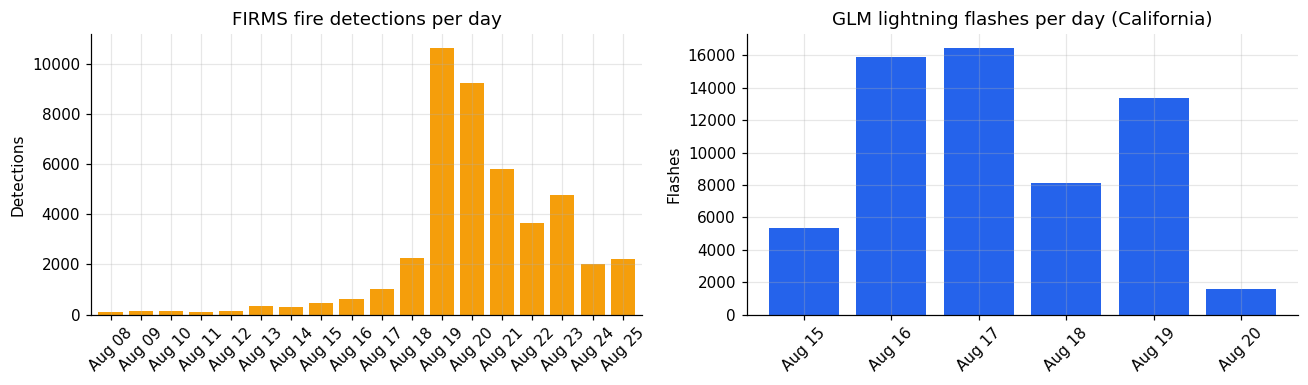

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
firms.groupby(firms.time.dt.date).size().plot.bar(ax=axes[0], color=ORANGE, width=0.8)
axes[0].set(title="FIRMS fire detections per day", xlabel="", ylabel="Detections")
glm.groupby(glm.flash_time.dt.date).size().plot.bar(ax=axes[1], color=BLUE, width=0.8)
axes[1].set(title="GLM lightning flashes per day (California)", xlabel="", ylabel="Flashes")
for ax in axes:
    ax.set_xticklabels([pd.Timestamp(t.get_text()).strftime("%b %d") for t in ax.get_xticklabels()], rotation=45)
plt.tight_layout(); plt.show()

Lightning peaked on Aug 16–17. Fire detections exploded a day or two later as the ignitions grew. That delay is why the matching looks *back* in time from each fire.

## 2. Matching prototype (D = 5 km, T = 48 h, new-fire rule 5 km)

In [4]:
run("match_prototype.py", "--d-km", "5", "--t-hours", "48", "--new-km", "5")

===== MATCHING SUMMARY =====
Parameters:   D = 5.0 km, T = 48.0 h; 'new fire' = nothing within 5.0 km in prior 7 days
Fire detections (nominal/high confidence):  41,647
New fires since 2020-08-15:                159
GLM flashes in sample:                      60,803  (2020-08-15 00:00:01.218433856 to 2020-08-20 23:59:46.772336959 UTC)
New fires within the flash sample's window: 139
New fires with >=1 candidate flash:          65  (47% of those in the window)
Median nearest-flash distance:              1.8 km
Median fire-to-flash lag:                   20.1 h
Run time:                                   2.1 s
Saved: new_fires.csv, fire_flash_matches.csv



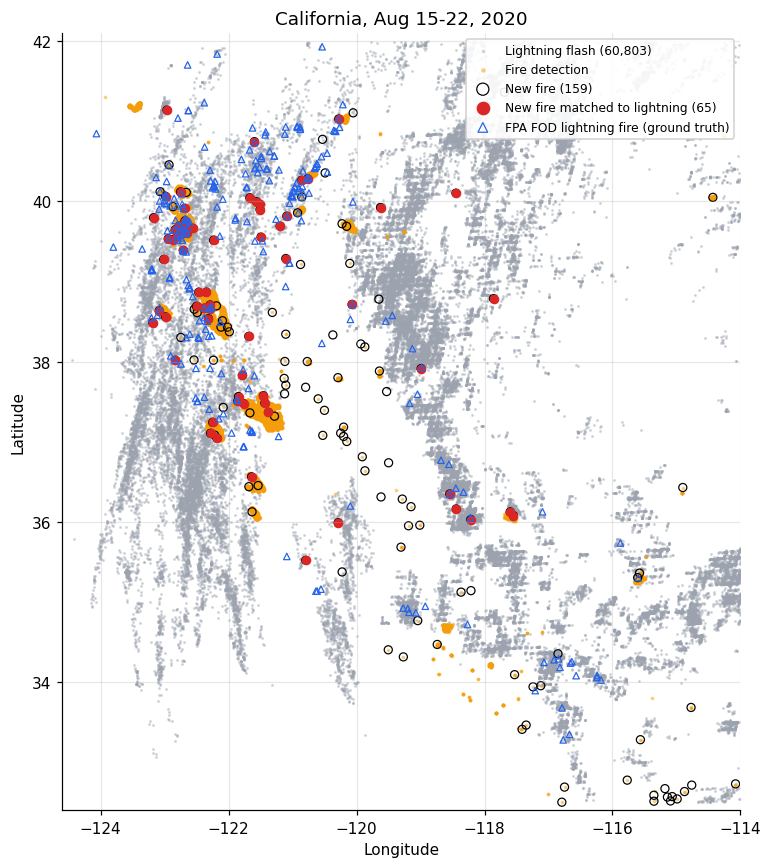

In [5]:
new = load("new_fires.csv", parse_dates=["time"])
matches = load("fire_flash_matches.csv", parse_dates=["fire_time"])
win = (firms.time >= "2020-08-15") & (firms.time < "2020-08-23")

fig, ax = plt.subplots(figsize=(7.5, 8))
ax.scatter(glm.lon, glm.lat, s=1, c=GREY, alpha=0.35, label=f"Lightning flash ({len(glm):,})")
ax.scatter(firms.longitude[win], firms.latitude[win], s=2, c=ORANGE, alpha=0.4, label="Fire detection")
ax.scatter(new.longitude, new.latitude, s=28, facecolors="none", edgecolors="black", lw=0.8, label=f"New fire ({len(new):,})")
ax.scatter(matches.fire_lon, matches.fire_lat, s=28, c=RED, label=f"New fire matched to lightning ({len(matches):,})")
ax.scatter(fod[fod.date.between("2020-08-15", "2020-08-22")].LONGITUDE,
           fod[fod.date.between("2020-08-15", "2020-08-22")].LATITUDE,
           s=18, marker="^", facecolors="none", edgecolors=BLUE, lw=0.8, label="FPA FOD lightning fire (ground truth)")
ax.set(xlim=(-124.6, -114), ylim=(32.4, 42.1), xlabel="Longitude", ylabel="Latitude",
       title="California, Aug 15-22, 2020")
ax.set_aspect(1 / np.cos(np.radians(37)))
ax.legend(loc="upper right", fontsize=8, markerscale=1.5, framealpha=0.9)
plt.tight_layout(); plt.show()

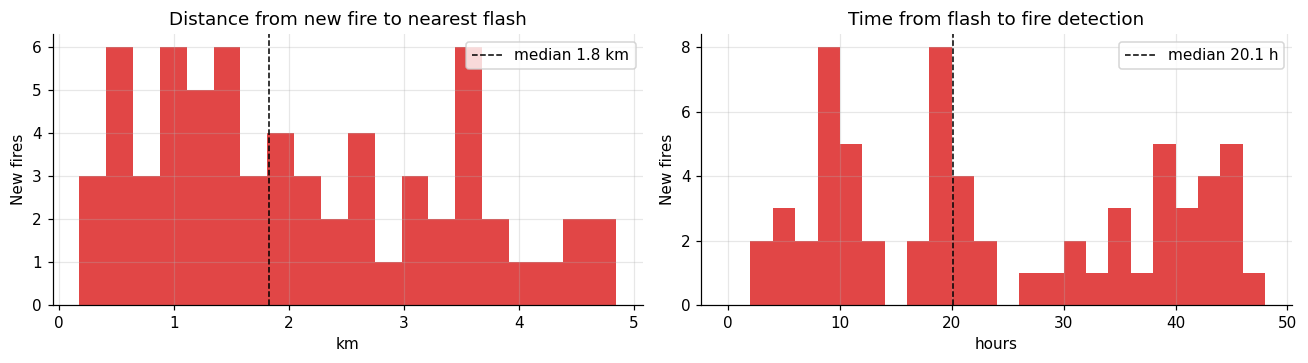

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(matches.nearest_flash_km, bins=20, color=RED, alpha=0.85)
axes[0].axvline(matches.nearest_flash_km.median(), color="black", ls="--", lw=1,
                label=f"median {matches.nearest_flash_km.median():.1f} km")
axes[0].set(title="Distance from new fire to nearest flash", xlabel="km", ylabel="New fires")
axes[1].hist(matches.lag_hours, bins=24, range=(0, 48), color=RED, alpha=0.85)
axes[1].axvline(matches.lag_hours.median(), color="black", ls="--", lw=1,
                label=f"median {matches.lag_hours.median():.1f} h")
axes[1].set(title="Time from flash to fire detection", xlabel="hours", ylabel="New fires")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

Many matched fires were detected 12+ hours after the flash. That fits *holdover* fires that smoulder before they grow large enough to see, combined with VIIRS passing over only about twice a day. Distances under a few km should be read with caution, since GLM's location accuracy is about 8 km.

## 3. Chance baseline and parameter tuning

**Is the match rate better than coincidence?** During a lightning siege, flashes are dense, so a random fire may have one nearby by chance.

- *First attempt:* shuffling flash **times** gave a real rate of 44% versus 72% for chance. That baseline was **biased**: real lightning was concentrated on Aug 16–17, and shuffling spread it across all six days, closer to the later fires.
- *Fix:* a **spatial-shift baseline** keeps every flash's real time but moves the whole lightning field 50–100 km in a random direction (3 shifts per setting).

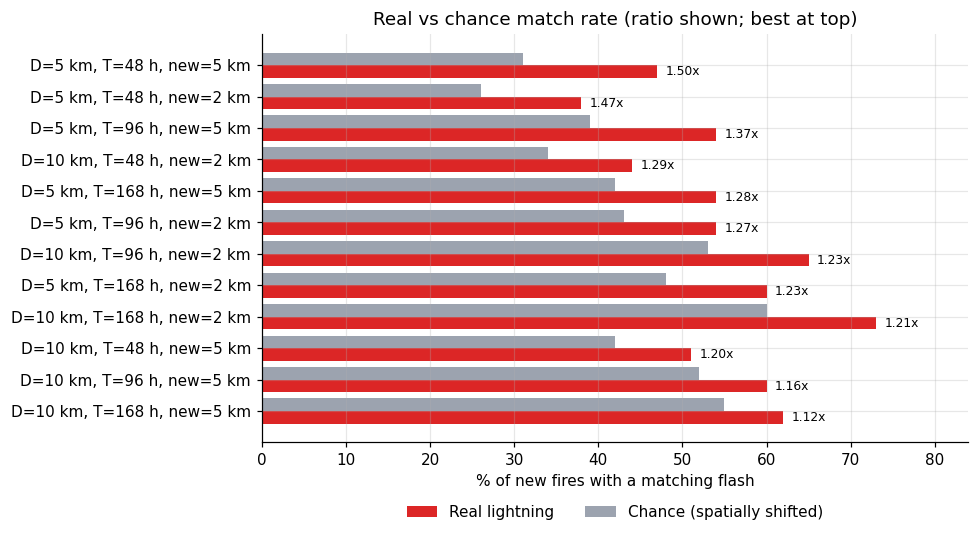

D_km,T_hours,new_fire_km,new_fires,real_rate,chance_rate,ratio
5,48,5,139,47%,31%,1.500000
5,48,2,305,38%,26%,1.470000
5,96,5,151,54%,39%,1.370000
10,48,2,305,44%,34%,1.290000
5,168,5,159,54%,42%,1.280000
5,96,2,337,54%,43%,1.270000
5,168,2,352,60%,48%,1.230000
10,96,2,337,65%,53%,1.230000
10,168,2,352,73%,60%,1.210000
10,48,5,139,51%,42%,1.200000


In [7]:
tune = load("tuning_results.csv")
tune["real"] = tune.real_rate.str.rstrip("%").astype(float)
tune["chance"] = tune.chance_rate.str.rstrip("%").astype(float)
tune["label"] = tune.apply(lambda r: f"D={r.D_km} km, T={r.T_hours} h, new={r.new_fire_km} km", axis=1)
t = tune.sort_values("ratio")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(t))
ax.barh(y - 0.2, t.real, height=0.4, color=RED, label="Real lightning")
ax.barh(y + 0.2, t.chance, height=0.4, color=GREY, label="Chance (spatially shifted)")
for yi, (r, ratio) in enumerate(zip(t.real, t.ratio)):
    ax.text(r + 1, yi - 0.2, f"{ratio:.2f}x", va="center", fontsize=8)
ax.set(yticks=y, yticklabels=t.label, xlabel="% of new fires with a matching flash",
       xlim=(0, t.real.max() * 1.15), title="Real vs chance match rate (ratio shown; best at top)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
tune.drop(columns=["real", "chance", "label"]).style.hide(axis="index")

All 12 settings beat chance (1.12–1.50x). The best was **D = 5 km, T = 48 h, new-fire rule 5 km**: 47% real versus 31% chance. Widening D or T raises both rates, but chance rises faster.

## 4. Validation against FPA FOD ground truth

In [8]:
run("validate.py")

===== VALIDATION SUMMARY =====
Match rule: within 5 km and 2 days of a recorded fire; window 2020-08-15 to 2020-08-22
FPA FOD lightning fires in window:      242  (60 were 10+ acres)

                                        All new fires   Lightning-matched
Fires flagged by pipeline                         139                  65
Precision (near a recorded fire)                  23%                 38%
Recall, all recorded fires                        19%                 16%
Recall, fires 10+ acres                           48%                 37%
F1 score                                         0.21                0.23

Saved: validation_fires.csv (each recorded fire and whether the pipeline found it)



In [9]:
val = load("validation_fires.csv", parse_dates=["date"])
val["size_class"] = np.where(val.FIRE_SIZE >= 10, "10+ acres", "under 10 acres")
summary = val.groupby("size_class").found_by_pipeline.agg(recorded="size", found="sum")
summary["recall"] = (summary.found / summary.recorded).map("{:.0%}".format)
display(summary)
cols = [c for c in ["FIRE_NAME", "COMPLEX_NAME", "date", "FIRE_SIZE", "found_by_pipeline"] if c in val]
print("Largest recorded lightning fires in the window:")
val.sort_values("FIRE_SIZE", ascending=False)[cols].head(15).style.hide(axis="index")

,recorded,found,recall
size_class,,,
10+ acres,60,22,37%
under 10 acres,182,17,9%


Largest recorded lightning fires in the window:


FIRE_NAME,COMPLEX_NAME,date,FIRE_SIZE,found_by_pipeline
DOE,AUGUST COMPLEX,2020-08-16 00:00:00,589368.000000,True
HOPKINS,AUGUST COMPLEX,2020-08-17 00:00:00,328363.000000,False
CLAREMONT,NORTH COMPLEX,2020-08-17 00:00:00,318776.000000,False
HENNESSEY,LNU LIGHTNING COMPLEX,2020-08-17 00:00:00,305651.200000,True
CASTLE,SQF COMPLEX,2020-08-19 00:00:00,174178.000000,False
W-5 COLD SPRINGS,nan,2020-08-18 00:00:00,84817.000000,True
WALLBRIDGE,LNU LIGHTNING COMPLEX,2020-08-17 00:00:00,55209.000000,True
SHF ELKHORN,AUGUST COMPLEX,2020-08-18 00:00:00,51576.700000,True
DOME,nan,2020-08-15 00:00:00,43273.000000,False
SHEEP,NORTH COMPLEX,2020-08-17 00:00:00,29570.000000,True


The lightning filter raises precision from 23% to 38%. Recall is low overall because most recorded lightning fires were tiny, below what VIIRS can reliably detect, so recall on fires of 10+ acres is the fairer measure.

## 5. Streaming pipeline benchmarks

The Kafka → Spark Structured Streaming → MongoDB pipeline replayed 92,594 events (60,803 flashes and 31,791 fire detections) at three speeds. At every speed, it matched **the same 65 new fires as the pandas prototype (100% agreement)**.

replay_speed,events,replay_time_s,producer_events_per_s,spark_peak_events_per_s,new_fires_matched,agreement,latency_median_s,latency_p95_s
"3,600x",92594,188.800000,490,14734,65,100%,3.600000,4.000000
"36,000x",92594,18.900000,4887,24882,65,100%,3.300000,4.700000
max,92594,6.100000,15215,28809,65,100%,6.700000,7.300000


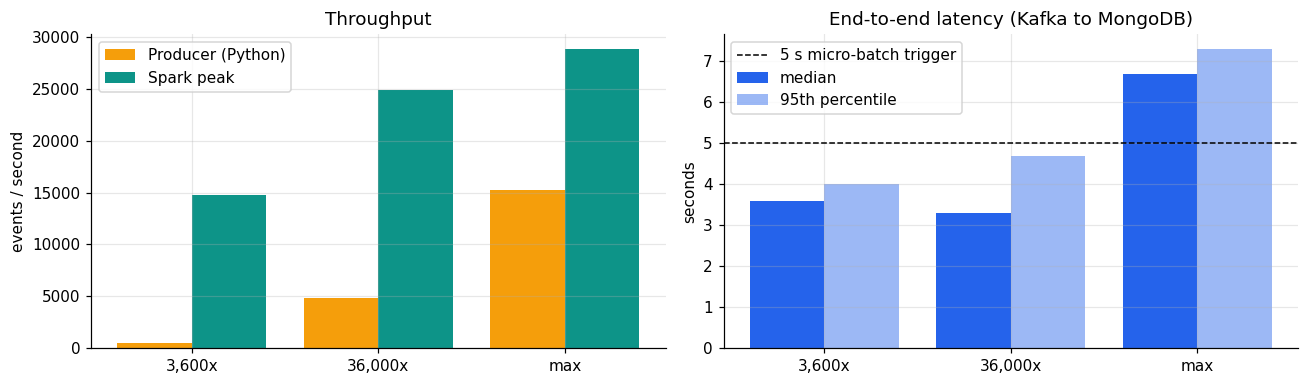

In [10]:
bench = load("benchmark_results.csv")
display(bench.style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
x = np.arange(len(bench))
axes[0].bar(x - 0.2, bench.producer_events_per_s, 0.4, color=ORANGE, label="Producer (Python)")
axes[0].bar(x + 0.2, bench.spark_peak_events_per_s, 0.4, color=TEAL, label="Spark peak")
axes[0].set(xticks=x, xticklabels=bench.replay_speed, ylabel="events / second", title="Throughput")
axes[0].legend()
axes[1].bar(x - 0.2, bench.latency_median_s, 0.4, color=BLUE, label="median")
axes[1].bar(x + 0.2, bench.latency_p95_s, 0.4, color=BLUE, alpha=0.45, label="95th percentile")
axes[1].axhline(5, color="black", ls="--", lw=1, label="5 s micro-batch trigger")
axes[1].set(xticks=x, xticklabels=bench.replay_speed, ylabel="seconds", title="End-to-end latency (Kafka to MongoDB)")
axes[1].legend()
plt.tight_layout(); plt.show()

Latency stays near the 5-second micro-batch interval at every speed, so Spark isn't falling behind. The Python producer, not Spark, limits throughput. The real event rate in this period averaged about 0.13 events per second, which leaves large headroom for real-time use.

## 6. Precision/recall trade-off against FPA FOD

`pr_sweep.py` reran the matching and validation for D = 2, 5 and 10 km and T = 24–168 h. Every setting beat the unfiltered baseline. 2 km was too tight for GLM's ~8 km location accuracy, and 48 h was the best time window. 5 km and 10 km performed about the same.

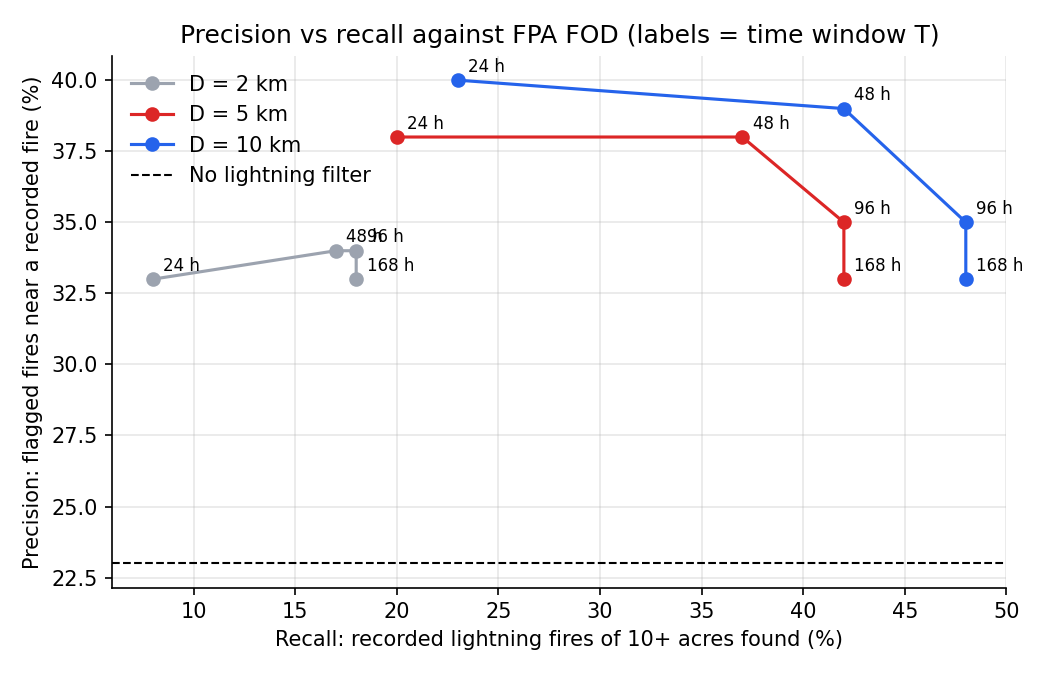

D_km,T_hours,fires_flagged,precision,recall_all,recall_10plus_acres,f1
10,96,91,35%,19%,48%,0.250000
10,48,71,39%,17%,42%,0.240000
10,168,97,33%,19%,48%,0.240000
5,48,65,38%,16%,37%,0.230000
5,96,81,35%,17%,42%,0.230000
5,168,84,33%,17%,42%,0.230000
10,24,42,40%,12%,23%,0.190000
5,24,39,38%,12%,20%,0.180000
2,96,38,34%,7%,18%,0.120000
2,168,39,33%,7%,18%,0.120000


In [11]:
sweep = load("pr_sweep.csv")
from IPython.display import Image
display(Image("pr_tradeoff.png", width=650))
show = sweep.sort_values("f1", ascending=False).copy()
for c in ["precision", "recall_all", "recall_10plus_acres"]:
    show[c] = (show[c] * 100).round().astype(int).astype(str) + "%"
show.style.hide(axis="index")

## 7. MongoDB geospatial queries

`mongo_bench.py` loaded the 60,803 flashes into MongoDB and, for each of the 139 new fires, queried for flashes within 5 km and the prior 48 h, with three index setups.

index,index_build_s,median_query_ms,p95_query_ms,total_s,avg_docs_examined,fires_matched
No index (full scan),0.000000,36.640000,41.030000,4.670000,60803,65
2dsphere on location,0.170000,0.570000,0.720000,0.080000,10,65
2dsphere + flash_time,0.170000,0.560000,0.700000,0.080000,6,65


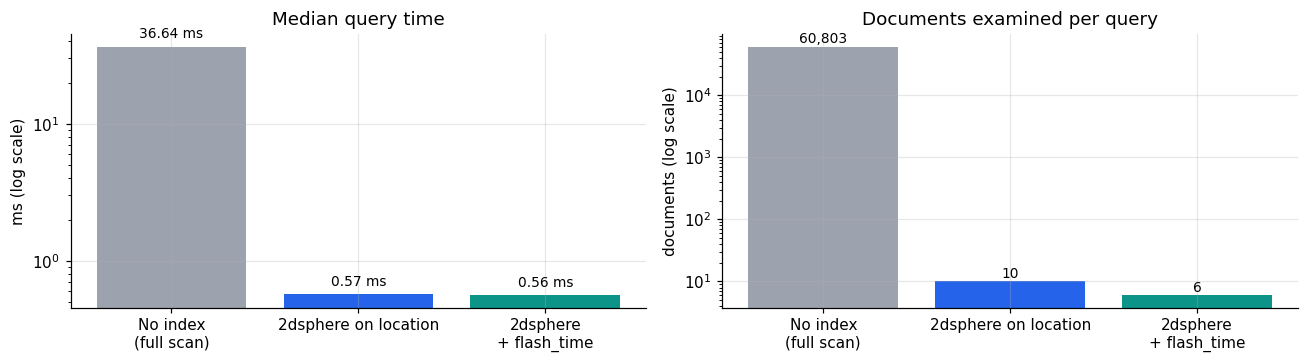

In [12]:
mongo = load("mongo_benchmark.csv")
display(mongo.style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
labels = mongo["index"].str.replace(" (full scan)", "\n(full scan)", regex=False).str.replace(" + ", "\n+ ", regex=False)
axes[0].bar(labels, mongo.median_query_ms, color=[GREY, BLUE, TEAL])
axes[0].set(yscale="log", ylabel="ms (log scale)", title="Median query time")
axes[1].bar(labels, mongo.avg_docs_examined, color=[GREY, BLUE, TEAL])
axes[1].set(yscale="log", ylabel="documents (log scale)", title="Documents examined per query")
for ax, col, fmt in [(axes[0], "median_query_ms", "{:.2f} ms"), (axes[1], "avg_docs_examined", "{:,}")]:
    for i, v in enumerate(mongo[col]):
        ax.text(i, v * 1.15, fmt.format(v), ha="center", fontsize=9)
plt.tight_layout(); plt.show()

The 2dsphere index made queries about 64x faster (36.6 ms to 0.57 ms) and cut the documents examined per query from 60,803 to 10. Every setup matched the same 65 fires as the prototype and the Spark stream.

## 8. Remaining work

- Detect new fires inside the stream (Spark state, Bloom filter, or MongoDB `$near` in `foreachBatch`)
- ~~MongoDB geospatial query benchmarks~~ ✅ Done (see README)
- Snowflake load and MongoDB vs Snowflake comparison
- Producer extensions: read GLM directly from S3, true 1x replay
- Broader evaluation: more days, NIFC perimeters, named complexes
- Final report and slides (due Nov 17)

Details are in `README.md`.